In [1]:
from pathlib import Path
import random
import copy
import numpy as np
import pandas as pd
import joblib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    hamming_loss, classification_report
)

import matplotlib.pyplot as plt

In [2]:
SEED = 42

EPOCHS = 30
HIDDEN_DIM = 32
DROPOUT = 0.35

LEARNING_RATE = 1e-4
BATCH_SIZE = 64
WEIGHT_DECAY = 1e-3

EARLY_STOPPING_PATIENCE = 5

In [3]:
## defining paths

GRAPH_DIR = Path(".")
CHECKPOINT_PATH = Path("graphsage_best_model.pt")
METRICS_PATH = Path("graphsage_metrics.csv")

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Device: cuda


## 1). Loading Train-val-test graphs

In [5]:
def load_graphs(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

In [6]:
train_graphs = load_graphs(GRAPH_DIR / "train_graphs.pt")
validation_graphs = load_graphs(GRAPH_DIR / "validation_graphs.pt")
test_graphs = load_graphs(GRAPH_DIR / "test_graphs.pt")

In [7]:
## loading the saved preprocessing objects

preprocessing_objects = joblib.load(
    GRAPH_DIR / "preprocessing_objects.joblib"
)

tactic_encoder = preprocessing_objects["tactic_encoder"]
mitre_encoder = preprocessing_objects["mitre_encoder"]



In [8]:
print("Training graphs:", len(train_graphs))
print("Validation graphs:", len(validation_graphs))
print("Test graphs:", len(test_graphs))
print("Tactic classes:", len(tactic_encoder.classes_))
print("MITRE classes:", len(mitre_encoder.classes_))

Training graphs: 20149
Validation graphs: 2519
Test graphs: 2518
Tactic classes: 13
MITRE classes: 27


## 2). Model Architecture

Three prediction heads to solve below:

- Binary attack detection
- Multi-label tactic prediction
- Multi-label MITRE technique prediction

In [9]:
class GraphSAGEEdgeClassifier(nn.Module):
    def __init__(
        self,
        node_input_dim,
        edge_input_dim,
        hidden_dim,
        tactic_dim,
        mitre_dim,
        dropout=0.3
    ):
        super().__init__()

        self.conv1 = SAGEConv(node_input_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.dropout = dropout

        edge_input_size = hidden_dim * 2 + edge_input_dim

        ## head for binary classification (normal or attack)
        self.binary_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        ## prediction head for Tactic classification
        
        self.tactic_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, tactic_dim)
        )

        ## Prediction head for technique classification
        
        self.mitre_head = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, mitre_dim)
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        source_nodes = edge_index[0]
        destination_nodes = edge_index[1]

        edge_representation = torch.cat(
            [
                x[source_nodes],
                x[destination_nodes],
                data.edge_attr
            ],
            dim=1
        )

        ## outputs
        
        binary_logits = self.binary_head(edge_representation).squeeze(1)
        tactic_logits = self.tactic_head(edge_representation)
        mitre_logits = self.mitre_head(edge_representation)

        return binary_logits, tactic_logits, mitre_logits

## 3). Creating Data Loaders

In [10]:
train_loader = DataLoader(
    train_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 4). Defining Optimizer and Instantiating model

In [11]:
## one sample

example_graph = train_graphs[0]

In [12]:
# instantiating model
model = GraphSAGEEdgeClassifier(
    node_input_dim=example_graph.x.shape[1],
    edge_input_dim=example_graph.edge_attr.shape[1],
    hidden_dim=HIDDEN_DIM,
    tactic_dim=train_graphs[0].y_tactic.shape[1],
    mitre_dim=train_graphs[0].y_mitre.shape[1],
    dropout=DROPOUT
).to(DEVICE)

In [13]:
## defining optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

In [14]:
print(model)

GraphSAGEEdgeClassifier(
  (conv1): SAGEConv(22, 32, aggr=mean)
  (conv2): SAGEConv(32, 32, aggr=mean)
  (binary_head): Sequential(
    (0): Linear(in_features=120, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.35, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
  (tactic_head): Sequential(
    (0): Linear(in_features=120, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.35, inplace=False)
    (3): Linear(in_features=32, out_features=13, bias=True)
  )
  (mitre_head): Sequential(
    (0): Linear(in_features=120, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.35, inplace=False)
    (3): Linear(in_features=32, out_features=27, bias=True)
  )
)


## 5). Defining Loss and Training functions

In [15]:
## computing weights from training data to address class imbalance
binary_labels = torch.cat([
    graph.y_binary for graph in train_graphs
])

tactic_labels = torch.cat([
    graph.y_tactic for graph in train_graphs
])

mitre_labels = torch.cat([
    graph.y_mitre for graph in train_graphs
])

def softened_pos_weight(labels, max_weight):
    labels = labels.float()
    positives = labels.sum(dim=0)
    negatives = labels.shape[0] - positives

    ratio = negatives / positives.clamp_min(1.0)

    return ratio.sqrt().clamp(
        min=1.0,
        max=max_weight
    ).to(DEVICE)


binary_pos_weight = torch.tensor(1.0, device=DEVICE)

tactic_pos_weight = softened_pos_weight(
    tactic_labels, max_weight=5.0
)

mitre_pos_weight = softened_pos_weight(
    mitre_labels, max_weight=5.0
)

print("Binary weight:", binary_pos_weight)
print("Tactic weights:", tactic_pos_weight)
print("MITRE weights:", mitre_pos_weight)

Binary weight: tensor(1., device='cuda:0')
Tactic weights: tensor([5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 4.1006, 5.0000], device='cuda:0')
MITRE weights: tensor([5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000,
        5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 5.0000, 4.1240],
       device='cuda:0')


In [16]:
def get_loss_mask(batch):
    if hasattr(batch, "loss_mask"):
        return batch.loss_mask.bool()
    return torch.ones(
        batch.edge_attr.shape[0],
        dtype=torch.bool,
        device=batch.edge_attr.device
    )


def compute_loss(outputs, batch, loss_mask=None):
    binary_logits, tactic_logits, mitre_logits = outputs

    if loss_mask is None:
        loss_mask = get_loss_mask(batch)

    binary_target = batch.y_binary.float()
    tactic_target = batch.y_tactic.float()
    mitre_target = batch.y_mitre.float()

    binary_loss = F.binary_cross_entropy_with_logits(
        binary_logits[loss_mask],
        binary_target[loss_mask],
        pos_weight=binary_pos_weight
    )

    tactic_loss = F.binary_cross_entropy_with_logits(
        tactic_logits[loss_mask],
        tactic_target[loss_mask],
        pos_weight=tactic_pos_weight
    )

    mitre_loss = F.binary_cross_entropy_with_logits(
        mitre_logits[loss_mask],
        mitre_target[loss_mask],
        pos_weight=mitre_pos_weight
    )

    total_loss = (
    1.0 * binary_loss
    + 0.25 * tactic_loss
    + 0.25 * mitre_loss
)

    return (
        total_loss,
        binary_loss,
        tactic_loss,
        mitre_loss
    )

In [17]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total_edges = 0

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()

        outputs = model(batch)
        loss, _, _, _ = compute_loss(outputs, batch)
        loss.backward()
        optimizer.step()

        selected_edges = int(get_loss_mask(batch).sum().item())
        total_loss += loss.item() * selected_edges
        total_edges += selected_edges

    return total_loss / max(total_edges, 1)

## 6). Evaluation metrics

In [18]:
def safe_roc_auc(y_true, y_score):
    try:
        return roc_auc_score(y_true, y_score)
    except ValueError:
        return np.nan


def safe_average_precision(y_true, y_score):
    try:
        return average_precision_score(y_true, y_score)
    except ValueError:
        return np.nan


def evaluate_model(model, loader, threshold=0.5):
    model.eval()

    all_binary_true = []
    all_binary_prob = []
    all_tactic_true = []
    all_tactic_prob = []
    all_mitre_true = []
    all_mitre_prob = []

    total_loss = 0.0
    total_edges = 0

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            outputs = model(batch)
            loss, _, _, _ = compute_loss(outputs, batch)

            mask = get_loss_mask(batch)
            selected_edges = int(mask.sum().item())
            total_loss += loss.item() * selected_edges
            total_edges += selected_edges

            binary_logits, tactic_logits, mitre_logits = outputs

            all_binary_true.append(batch.y_binary[mask].cpu().numpy())
            all_binary_prob.append(
                torch.sigmoid(binary_logits[mask]).cpu().numpy()
            )
            all_tactic_true.append(batch.y_tactic[mask].cpu().numpy())
            all_tactic_prob.append(
                torch.sigmoid(tactic_logits[mask]).cpu().numpy()
            )
            all_mitre_true.append(batch.y_mitre[mask].cpu().numpy())
            all_mitre_prob.append(
                torch.sigmoid(mitre_logits[mask]).cpu().numpy()
            )

    binary_true = np.concatenate(all_binary_true)
    binary_prob = np.concatenate(all_binary_prob)
    tactic_true = np.concatenate(all_tactic_true)
    tactic_prob = np.concatenate(all_tactic_prob)
    mitre_true = np.concatenate(all_mitre_true)
    mitre_prob = np.concatenate(all_mitre_prob)

    binary_pred = (binary_prob >= threshold).astype(int)
    tactic_pred = (tactic_prob >= threshold).astype(int)
    mitre_pred = (mitre_prob >= threshold).astype(int)

    metrics = {
        "loss": total_loss / max(total_edges, 1),

        "binary_accuracy": accuracy_score(binary_true, binary_pred),
        "binary_precision": precision_score(
            binary_true, binary_pred, zero_division=0
        ),
        "binary_recall": recall_score(
            binary_true, binary_pred, zero_division=0
        ),
        "binary_f1": f1_score(
            binary_true, binary_pred, zero_division=0
        ),
        "binary_roc_auc": safe_roc_auc(binary_true, binary_prob),
        "binary_pr_auc": safe_average_precision(
            binary_true, binary_prob
        ),

        "tactic_micro_f1": f1_score(
            tactic_true, tactic_pred, average="micro", zero_division=0
        ),
        "tactic_macro_f1": f1_score(
            tactic_true, tactic_pred, average="macro", zero_division=0
        ),
        "tactic_hamming_loss": hamming_loss(
            tactic_true, tactic_pred
        ),
        "tactic_exact_match": np.mean(
            np.all(tactic_true == tactic_pred, axis=1)
        ),

        "mitre_micro_f1": f1_score(
            mitre_true, mitre_pred, average="micro", zero_division=0
        ),
        "mitre_macro_f1": f1_score(
            mitre_true, mitre_pred, average="macro", zero_division=0
        ),
        "mitre_hamming_loss": hamming_loss(
            mitre_true, mitre_pred
        ),
        "mitre_exact_match": np.mean(
            np.all(mitre_true == mitre_pred, axis=1)
        )
    }

    outputs = {
        "binary_true": binary_true,
        "binary_prob": binary_prob,
        "tactic_true": tactic_true,
        "tactic_prob": tactic_prob,
        "mitre_true": mitre_true,
        "mitre_prob": mitre_prob
    }

    return metrics, outputs

## 7). Training Loop

In [19]:
# Separate filenames preserve your previous experiment.
CHECKPOINT_PATH = Path("graphsage_exp1_best_model.pt")
METRICS_PATH = Path("graphsage_exp1_metrics.csv")

best_validation_f1 = -np.inf
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):

    optimization_loss = train_one_epoch(
        model, train_loader, optimizer
    )

    train_metrics, _ = evaluate_model(
        model, train_loader, threshold=0.5
    )

    validation_metrics, _ = evaluate_model(
        model, validation_loader, threshold=0.5
    )

    # Both losses below are measured with dropout disabled.
    row = {
        "epoch": epoch,
        "optimization_loss": optimization_loss,
        "train_loss": train_metrics["loss"],
        "validation_loss": validation_metrics["loss"],
    }

    for metric in [
        "binary_precision",
        "binary_recall",
        "binary_f1",
        "binary_pr_auc",  # Computed as average precision (AP)
        "tactic_micro_f1",
        "tactic_macro_f1",
        "mitre_micro_f1",
        "mitre_macro_f1",
    ]:
        row[f"train_{metric}"] = train_metrics[metric]
        row[f"validation_{metric}"] = validation_metrics[metric]

    history.append(row)
    pd.DataFrame(history).to_csv(METRICS_PATH, index=False)

    current_f1 = validation_metrics["binary_f1"]

    if current_f1 > best_validation_f1 + 1e-4:
        best_validation_f1 = current_f1
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "model_config": {
                    "node_input_dim": example_graph.x.shape[1],
                    "edge_input_dim": example_graph.edge_attr.shape[1],
                    "hidden_dim": HIDDEN_DIM,
                    "tactic_dim": train_graphs[0].y_tactic.shape[1],
                    "mitre_dim": train_graphs[0].y_mitre.shape[1],
                    "dropout": DROPOUT,
                },
                "best_validation_f1": best_validation_f1,
                "validation_metrics": validation_metrics,
                "threshold": 0.5,
                "loss_weights": {
                    "binary": 1.0,
                    "tactic": 0.25,
                    "mitre": 0.25,
                },
                "pos_weights": {
                    "binary": binary_pos_weight.detach().cpu(),
                    "tactic": tactic_pos_weight.detach().cpu(),
                    "mitre": mitre_pos_weight.detach().cpu(),
                },
            },
            CHECKPOINT_PATH,
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['binary_f1']:.4f} | "
        f"Val P: {validation_metrics['binary_precision']:.4f} | "
        f"Val R: {validation_metrics['binary_recall']:.4f} | "
        f"Val F1: {current_f1:.4f} | "
        f"Val AP: {validation_metrics['binary_pr_auc']:.4f}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            f"Early stopping: no validation binary F1 improvement "
            f"for {EARLY_STOPPING_PATIENCE} epochs."
        )
        break

print("Best validation binary F1:", round(best_validation_f1, 4))
print("Checkpoint:", CHECKPOINT_PATH)
print("Metrics:", METRICS_PATH)

Epoch 01 | Train Loss: 0.3172 | Val Loss: 0.3243 | Train F1: 0.0000 | Val P: 0.0000 | Val R: 0.0000 | Val F1: 0.0000 | Val AP: 0.4112
Epoch 02 | Train Loss: 0.1264 | Val Loss: 0.1229 | Train F1: 0.7783 | Val P: 0.7869 | Val R: 0.7579 | Val F1: 0.7721 | Val AP: 0.9108
Epoch 03 | Train Loss: 0.0796 | Val Loss: 0.0786 | Train F1: 0.8213 | Val P: 0.8234 | Val R: 0.8541 | Val F1: 0.8385 | Val AP: 0.9618
Epoch 04 | Train Loss: 0.0571 | Val Loss: 0.0579 | Train F1: 0.9408 | Val P: 0.9642 | Val R: 0.9300 | Val F1: 0.9468 | Val AP: 0.9828
Epoch 05 | Train Loss: 0.0446 | Val Loss: 0.0453 | Train F1: 0.9393 | Val P: 0.9628 | Val R: 0.9302 | Val F1: 0.9462 | Val AP: 0.9904
Epoch 06 | Train Loss: 0.0370 | Val Loss: 0.0377 | Train F1: 0.9775 | Val P: 0.9671 | Val R: 0.9907 | Val F1: 0.9788 | Val AP: 0.9918
Epoch 07 | Train Loss: 0.0321 | Val Loss: 0.0328 | Train F1: 0.9796 | Val P: 0.9703 | Val R: 0.9907 | Val F1: 0.9804 | Val AP: 0.9933
Epoch 08 | Train Loss: 0.0300 | Val Loss: 0.0306 | Train F1: 0

In [20]:
## evaluating checkpoint 

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False,
)

model.load_state_dict(checkpoint["model_state_dict"])

best_validation_metrics, _ = evaluate_model(
    model,
    validation_loader,
    threshold=0.5,
)

print("Selected epoch:", checkpoint["epoch"])
print("\nBest-checkpoint validation metrics:")
print(pd.Series(best_validation_metrics).round(4))

Selected epoch: 30

Best-checkpoint validation metrics:
loss                   0.0177
binary_accuracy        0.9989
binary_precision       0.9957
binary_recall          0.9907
binary_f1              0.9932
binary_roc_auc         0.9992
binary_pr_auc          0.9970
tactic_micro_f1        0.7615
tactic_macro_f1        0.1643
tactic_hamming_loss    0.0031
tactic_exact_match     0.9781
mitre_micro_f1         0.7611
mitre_macro_f1         0.0672
mitre_hamming_loss     0.0015
mitre_exact_match      0.9782
dtype: float64


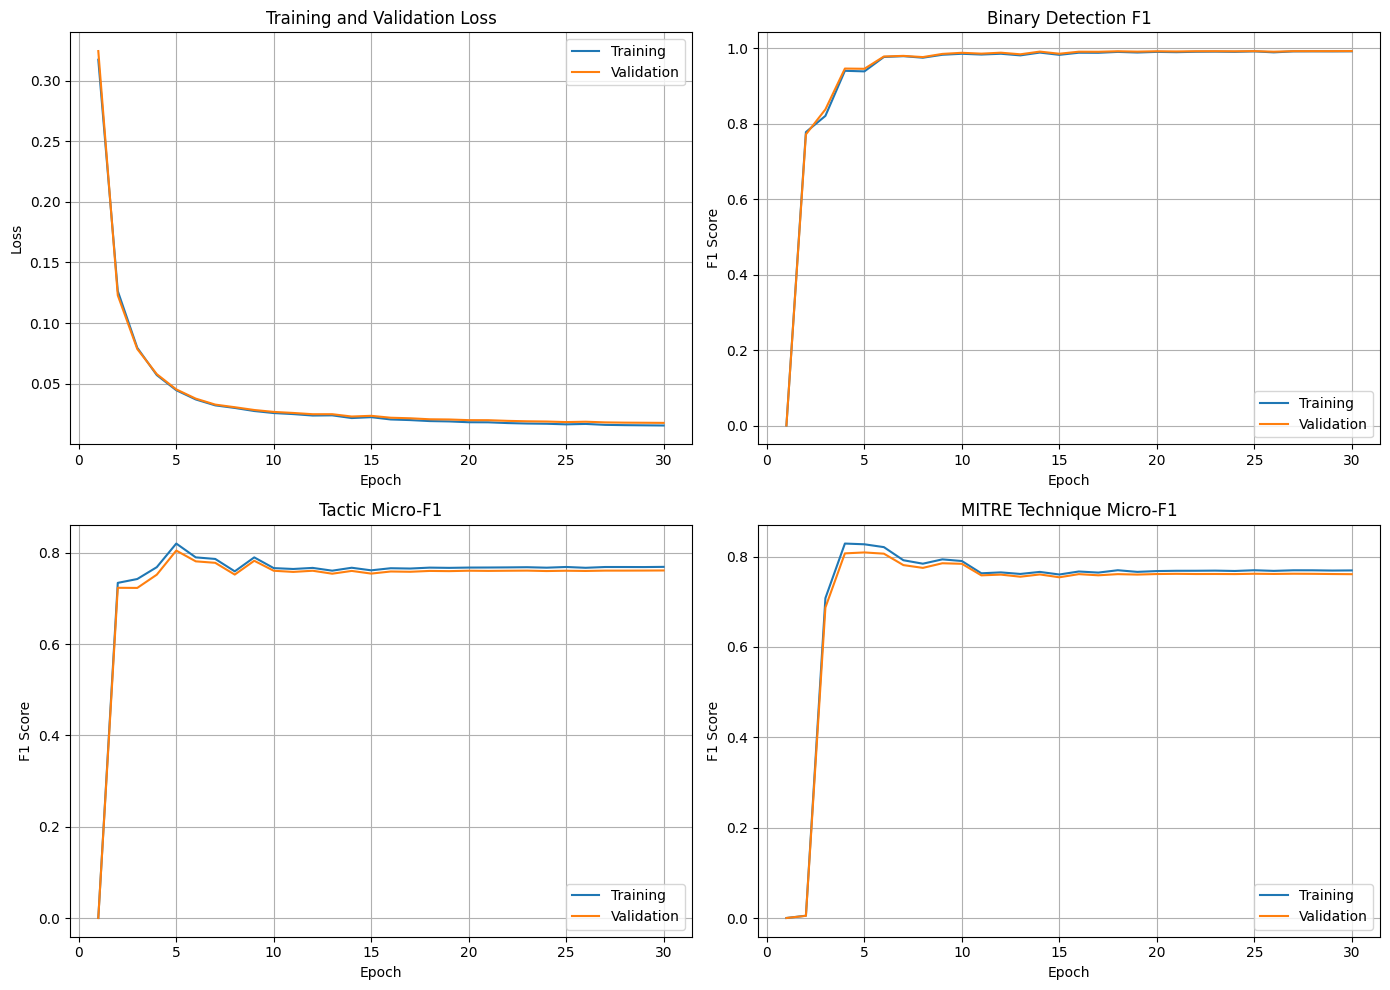

In [21]:

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Loss
axes[0, 0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training"
)

axes[0, 0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation"
)

axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

# Binary F1
axes[0, 1].plot(
    history_df["epoch"],
    history_df["train_binary_f1"],
    label="Training"
)

axes[0, 1].plot(
    history_df["epoch"],
    history_df["validation_binary_f1"],
    label="Validation"
)

axes[0, 1].set_title("Binary Detection F1")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("F1 Score")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Tactic F1
axes[1, 0].plot(
    history_df["epoch"],
    history_df["train_tactic_micro_f1"],
    label="Training"
)

axes[1, 0].plot(
    history_df["epoch"],
    history_df["validation_tactic_micro_f1"],
    label="Validation"
)

axes[1, 0].set_title("Tactic Micro-F1")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("F1 Score")
axes[1, 0].legend()
axes[1, 0].grid(True)

# MITRE F1
axes[1, 1].plot(
    history_df["epoch"],
    history_df["train_mitre_micro_f1"],
    label="Training"
)

axes[1, 1].plot(
    history_df["epoch"],
    history_df["validation_mitre_micro_f1"],
    label="Validation"
)

axes[1, 1].set_title("MITRE Technique Micro-F1")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("F1 Score")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

## 8). Evaluating heads on validation and test dataset

In [22]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)

validation_metrics, validation_outputs = evaluate_model(
    model, validation_loader
)
test_metrics, test_outputs = evaluate_model(
    model, test_loader
)

metrics_table = pd.DataFrame([
    {"split": "validation", **validation_metrics},
    {"split": "test", **test_metrics}
])

display(metrics_table.T)
metrics_table.to_csv(METRICS_PATH, index=False)
print("Metrics saved to:", METRICS_PATH)

,0,1
split,validation,test
loss,0.017694,0.014444
binary_accuracy,0.998868,0.998887
binary_precision,0.995703,0.995219
binary_recall,0.990736,0.991182
binary_f1,0.993213,0.993196
binary_roc_auc,0.999219,0.999127
binary_pr_auc,0.996965,0.996997
tactic_micro_f1,0.761532,0.801346
tactic_macro_f1,0.164286,0.148381


Metrics saved to: graphsage_exp1_metrics.csv


## 9). Few-shot 

In [23]:
# def add_few_shot_loss_masks(graphs, attack_fraction, seed=42):
#     rng = np.random.default_rng(seed)
#     few_shot_graphs = []

#     for graph in graphs:
#         graph_copy = copy.deepcopy(graph)
#         labels = graph_copy.y_binary.cpu().numpy().astype(int)

#         attack_positions = np.flatnonzero(labels == 1)
#         benign_positions = np.flatnonzero(labels == 0)

#         if len(attack_positions) == 0:
#             selected_positions = benign_positions
#         else:
#             number_of_attacks = max(1, int(
#                 np.ceil(len(attack_positions) * attack_fraction)
#             ))
#             number_of_attacks = min(
#                 number_of_attacks, len(attack_positions)
#             )

#             selected_attacks = rng.choice(
#                 attack_positions,
#                 size=number_of_attacks,
#                 replace=False
#             )

#             number_of_benign = min(
#                 len(benign_positions),
#                 len(selected_attacks)
#             )

#             if number_of_benign > 0:
#                 selected_benign = rng.choice(
#                     benign_positions,
#                     size=number_of_benign,
#                     replace=False
#                 )
#                 selected_positions = np.concatenate(
#                     [selected_attacks, selected_benign]
#                 )
#             else:
#                 selected_positions = selected_attacks

#         loss_mask = torch.zeros(
#             graph_copy.num_edges,
#             dtype=torch.bool
#         )
#         loss_mask[selected_positions] = True
#         graph_copy.loss_mask = loss_mask
#         few_shot_graphs.append(graph_copy)

#     return few_shot_graphs


# def run_few_shot_experiment(
#     attack_fraction,
#     epochs=10,
#     seed=42
# ):
#     few_shot_graphs = add_few_shot_loss_masks(
#         train_graphs,
#         attack_fraction=attack_fraction,
#         seed=seed
#     )

#     few_shot_loader = DataLoader(
#         few_shot_graphs,
#         batch_size=BATCH_SIZE,
#         shuffle=True
#     )

#     few_shot_model = GraphSAGEEdgeClassifier(
#         node_input_dim=example_graph.x.shape[1],
#         edge_input_dim=example_graph.edge_attr.shape[1],
#         hidden_dim=HIDDEN_DIM,
#         tactic_dim=train_graphs[0].y_tactic.shape[1],
#         mitre_dim=train_graphs[0].y_mitre.shape[1],
#         dropout=DROPOUT
#     ).to(DEVICE)

#     few_shot_optimizer = torch.optim.Adam(
#         few_shot_model.parameters(),
#         lr=LEARNING_RATE,
#         weight_decay=WEIGHT_DECAY
#     )

#     for epoch in range(epochs):
#         train_one_epoch(
#             few_shot_model,
#             few_shot_loader,
#             few_shot_optimizer
#         )

#     validation_result, _ = evaluate_model(
#         few_shot_model,
#         validation_loader
#     )
#     test_result, _ = evaluate_model(
#         few_shot_model,
#         test_loader
#     )

#     return {
#         "attack_fraction": attack_fraction,
#         "validation_binary_f1": validation_result["binary_f1"],
#         "validation_tactic_micro_f1": validation_result["tactic_micro_f1"],
#         "validation_mitre_micro_f1": validation_result["mitre_micro_f1"],
#         "test_binary_f1": test_result["binary_f1"],
#         "test_tactic_micro_f1": test_result["tactic_micro_f1"],
#         "test_mitre_micro_f1": test_result["mitre_micro_f1"]
#     }

In [24]:
# RUN_FEW_SHOT_EXPERIMENTS = True

# if RUN_FEW_SHOT_EXPERIMENTS:
#     few_shot_results = []

#     for fraction in [0.01, 0.05, 0.10]:
#         result = run_few_shot_experiment(
#             attack_fraction=fraction,
#             epochs=10,
#             seed=SEED
#         )
#         few_shot_results.append(result)

#     few_shot_table = pd.DataFrame(few_shot_results)
#     display(few_shot_table)
#     few_shot_table.to_csv(
#         "few_shot_metrics.csv",
#         index=False
#     )